# DHVC 순간장 — Ng et al. (2017) JFM 825 fig.2 양식

뜨거운 벽(z = 0) 근처 **z⁺ ≈ 15** 의 벽 평행 평면(x 연직·위로, y 스팬)에서 (위) 유동방향 속도 u/U_Δ, (아래) 온도 (Θ−Θ₀)/Δ.
U_Δ = √(gβΔH) 는 우리 자유낙하 무차원의 속도 단위라 u/U_Δ = U, Θ₀ = 평균 온도라 (Θ−Θ₀)/Δ = T.
케이스 = 검증 런의 마지막 체크포인트(mirror 벽·확장통계 런): Ra 1e5·1e6 (`restart_*_ext`, 384×192×96), 1e7 (`restart_1e7_mirror`, 832×416×192), 1e8 (`restart_1e8_ext`, 1536×340×768).
z⁺ = z u_τ/ν, ν = √(Pr/Ra), u_τ 는 같은 런의 통계 헤더 `u_tau_hot`. 평면은 z⁺ = 15 를 끼는 두 셀중심의 선형 보간, U 는 x-면 값을 셀중심으로 평균.
평면은 체크포인트에서 한 번만 뽑아 `instant_planes/plane_<Ra>.npz` 에 캐시한다(1e8 체크포인트 16 GB).

In [1]:
import glob, os, re, struct
import numpy as np
import matplotlib
try:
    get_ipython().run_line_magic("matplotlib", "inline")
except NameError:
    matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

APP = os.path.abspath(os.path.join(os.getcwd(), ".."))
CACHE = os.path.join(os.getcwd(), "instant_planes"); os.makedirs(CACHE, exist_ok=True)
Z_PLUS = 15.0
PRANDTL = 0.7
CASES = [  # (label, Ra, checkpoint dir, stats dir, gamma_z)
    ("1e5", 1e5, "restart_1e5_ext",    "out_1e5_ext",    2.6),
    ("1e6", 1e6, "restart_1e6_ext",    "out_1e6_ext",    2.6),
    ("1e7", 1e7, "restart_1e7_mirror", "out_1e7_mirror", 2.6),
    ("1e8", 1e8, "restart_1e8_ext",    "out_1e8_ext",    2.6),
]

def tanh_faces(n, length, gamma):  # grid/stretching.cpp make_tanh_faces 와 동일
    xi = np.arange(n + 1) / n
    f = 0.5 * length * (1 + np.tanh(0.5 * gamma * (2 * xi - 1)) / np.tanh(0.5 * gamma)); f[0], f[-1] = 0, length
    return f

def read_checkpoint_header(path):
    with open(path, "rb") as f:
        f.read(8); version, real_size = struct.unpack("ii", f.read(8)); step, t = struct.unpack("qd", f.read(16))
        ngx, ngy, ngz, nf, ns = struct.unpack("iiiii", f.read(20))
        for _ in range(ns): f.read(24)
        off = f.tell(); fields = {}
        for _ in range(nf):
            f.seek(off); name = f.read(16).split(b"\0")[0].decode(); fields[name] = off + 16; off += 16 + ngx * ngy * ngz * 8
    return dict(step=step, t=t, shape=(ngx, ngy, ngz), fields=fields)

def header_value(path, key):
    for l in open(path):
        if not l.startswith("#"): break
        m = re.search(rf"\b{key}=([-+\d.eE]+)", l)
        if m: return float(m.group(1))
    return None

def extract_plane(label, ra, ck_dir, stats_dir, gamma):
    cache = os.path.join(CACHE, f"plane_{label}.npz")
    if os.path.exists(cache): return dict(np.load(cache))
    ck = sorted(glob.glob(os.path.join(APP, ck_dir, "dhvc_ck_*.bin")))[-1]
    st = sorted(glob.glob(os.path.join(APP, stats_dir, "dhvc_stats_*.dat")))[-1]
    h = read_checkpoint_header(ck); ngx, ngy, ngz = h["shape"]
    nu = np.sqrt(PRANDTL / ra); u_tau = header_value(st, "u_tau_hot")
    zf = tanh_faces(ngz, 1.0, gamma); zc = 0.5 * (zf[1:] + zf[:-1]); z_target = Z_PLUS * nu / u_tau
    k = int(np.searchsorted(zc, z_target)) - 1; w = (z_target - zc[k]) / (zc[k + 1] - zc[k])
    planes = {}
    for name in ("U", "T"):
        a = np.memmap(ck, dtype=np.float64, mode="r", offset=h["fields"][name], shape=(ngx, ngy, ngz))
        p = (1 - w) * np.array(a[:, :, k]) + w * np.array(a[:, :, k + 1]); del a
        if name == "U": p = 0.5 * (p + np.roll(p, -1, axis=0))   # x-면 → 셀중심
        planes[name] = p
    out = dict(U=planes["U"], T=planes["T"], ra=ra, t=h["t"], step=h["step"], z=z_target, z_plus=Z_PLUS, u_tau=u_tau, nu=nu,
               k=k, ngx=ngx, ngy=ngy, ngz=ngz)
    np.savez_compressed(cache, **out)
    return out

data = {}
for label, ra, ck_dir, stats_dir, gamma in CASES:
    d = extract_plane(label, ra, ck_dir, stats_dir, gamma); data[label] = d
    print(f"Ra {label}: grid {int(d['ngx'])}x{int(d['ngy'])}x{int(d['ngz'])}  t={float(d['t']):.1f}  u_tau={float(d['u_tau']):.4f}  "
          f"z(z+=15)={float(d['z']):.4f} (between cells {int(d['k'])},{int(d['k'])+1})  "
          f"u range [{d['U'].min():.3f}, {d['U'].max():.3f}]  T range [{d['T'].min():.3f}, {d['T'].max():.3f}]")


Ra 1e5: grid 384x192x96  t=450.0  u_tau=0.1773  z(z+=15)=0.2239 (between cells 28,29)  u range [-0.620, 1.306]  T range [-0.197, 0.401]


Ra 1e6: grid 384x192x96  t=450.0  u_tau=0.1296  z(z+=15)=0.0969 (between cells 15,16)  u range [-0.357, 1.370]  T range [-0.115, 0.424]


Ra 1e7: grid 832x416x192  t=200.0  u_tau=0.0993  z(z+=15)=0.0400 (between cells 15,16)  u range [-0.393, 1.410]  T range [-0.085, 0.461]


Ra 1e8: grid 1536x340x768  t=130.0  u_tau=0.0751  z(z+=15)=0.0167 (between cells 29,30)  u range [-0.710, 1.473]  T range [-0.157, 0.492]


## 그림 — (a–d) u/U_Δ, (e–h) (Θ−Θ₀)/Δ, z⁺ ≈ 15 (뜨거운 벽), 중력은 아래쪽

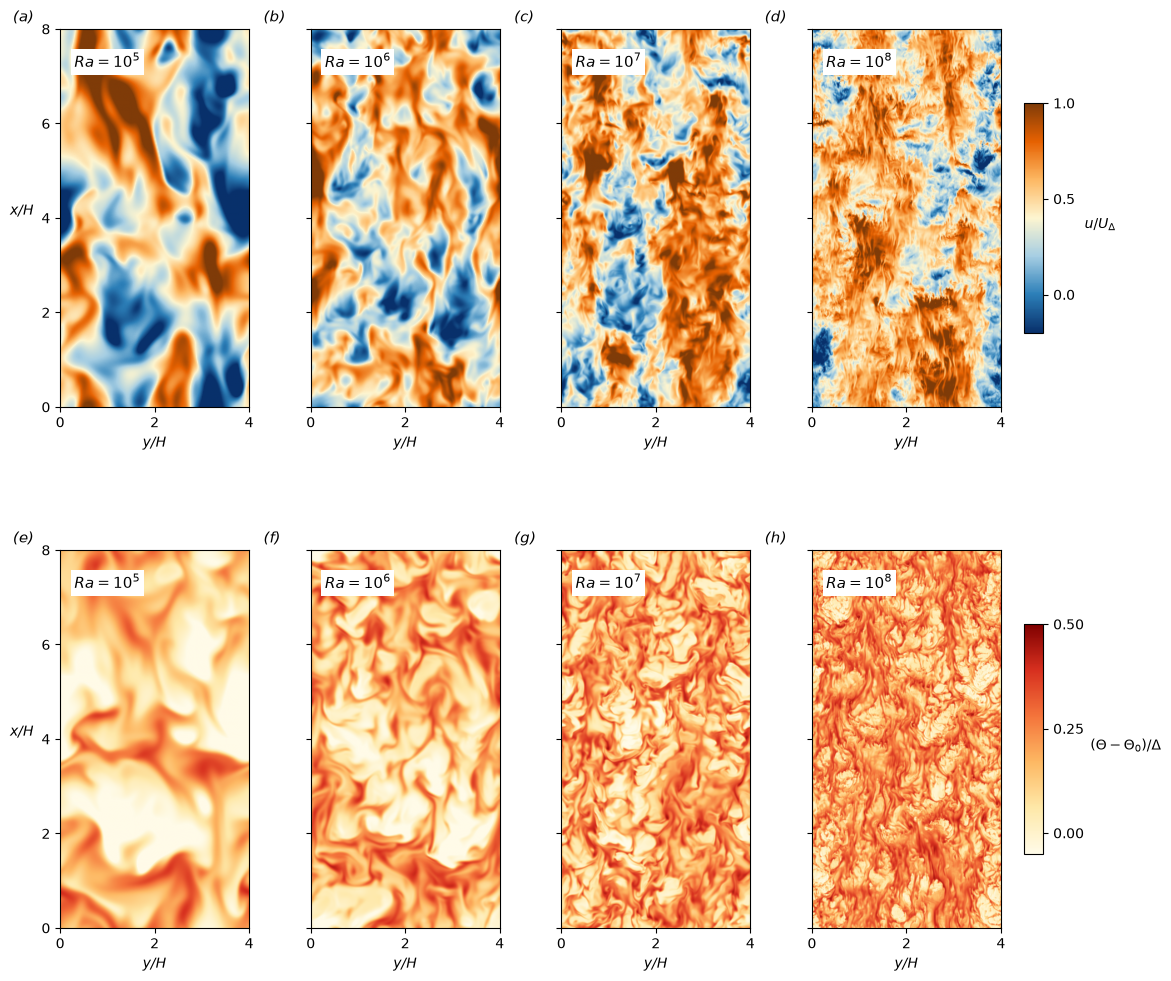

Ra 1e5: plane z+ = 15 (z = 0.2239 H), t = 450.0, mean u = 0.376, u_rms = 0.351, mean T = 0.105, T_rms = 0.120
Ra 1e6: plane z+ = 15 (z = 0.0969 H), t = 450.0, mean u = 0.457, u_rms = 0.273, mean T = 0.143, T_rms = 0.115
Ra 1e7: plane z+ = 15 (z = 0.0400 H), t = 200.0, mean u = 0.513, u_rms = 0.277, mean T = 0.181, T_rms = 0.107
Ra 1e8: plane z+ = 15 (z = 0.0167 H), t = 130.0, mean u = 0.521, u_rms = 0.236, mean T = 0.209, T_rms = 0.101


In [2]:
# 논문과 같은 색표: 속도 = 남색–하늘–미색–주황–갈색(−0.2..1.0), 온도 = 미색–주황–적갈(−0.05..0.5)
cmap_u = LinearSegmentedColormap.from_list("ng_u", ["#08306b", "#2c7fb8", "#a6cee3", "#fdf5d0", "#fdb863", "#e66101", "#7f3b08"])
cmap_t = LinearSegmentedColormap.from_list("ng_t", ["#fffbe8", "#fee8a8", "#fdb863", "#f4743b", "#d7301f", "#7f0000"])
U_LIM, T_LIM = (-0.2, 1.0), (-0.05, 0.5)
labels = list(data)
fig, axes = plt.subplots(2, len(labels), figsize=(2.6 * len(labels) + 1.2, 10.4), constrained_layout=True)
letters = "abcdefghijkl"
for col, lab in enumerate(labels):
    d = data[lab]; ngx, ngy = int(d["ngx"]), int(d["ngy"])
    for row, (field, cmap, lim) in enumerate((("U", cmap_u, U_LIM), ("T", cmap_t, T_LIM))):
        ax = axes[row, col]
        im = ax.imshow(d[field], origin="lower", extent=(0, 4, 0, 8), cmap=cmap, vmin=lim[0], vmax=lim[1],
                       interpolation="bilinear", aspect="equal")
        ax.set_xticks([0, 2, 4]); ax.set_yticks([0, 2, 4, 6, 8])
        ax.set_xlabel("y/H", fontstyle="italic")
        if col == 0: ax.set_ylabel("x/H", fontstyle="italic", rotation=0, labelpad=14)
        else: ax.set_yticklabels([])
        exponent = int(round(np.log10(float(d["ra"]))))
        ax.text(0.30, 7.3, rf"$Ra = 10^{exponent}$", fontsize=11, ha="left", va="center",
                bbox=dict(facecolor="white", edgecolor="none", pad=2.5))
        ax.text(-0.25, 1.02, f"({letters[row * len(labels) + col]})", transform=ax.transAxes, fontstyle="italic", fontsize=11)
        if col == len(labels) - 1:
            cb = fig.colorbar(im, ax=axes[row, :], shrink=0.45, aspect=12, pad=0.02)
            if field == "U": cb.set_ticks([0, 0.5, 1.0]); cb.set_label(r"$u/U_\Delta$", rotation=0, labelpad=18)
            else: cb.set_ticks([0, 0.25, 0.5]); cb.set_label(r"$(\Theta-\Theta_0)/\Delta$", rotation=0, labelpad=30)
SAVE = os.environ.get("DHVC_INSTANT_FIG")
if SAVE: fig.savefig(SAVE, dpi=110)
plt.show()
for lab in labels:
    d = data[lab]
    print(f"Ra {lab}: plane z+ = {float(d['z_plus']):.0f} (z = {float(d['z']):.4f} H), t = {float(d['t']):.1f}, "
          f"mean u = {d['U'].mean():.3f}, u_rms = {d['U'].std():.3f}, mean T = {d['T'].mean():.3f}, T_rms = {d['T'].std():.3f}")
